## Model 2: Polynomial Ridge Regression

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 1. Load Dataset

In [22]:
df = pd.read_csv("dataset/gas_turbine_processed.csv")
df.head()

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,NOX
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,81.952
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,82.377
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,83.776
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,82.505
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,82.028


### 2. Train Test Split

In [23]:
X = df.drop('NOX', axis=1)
y = df['NOX']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

### 3. Polynomial Feature Expansion (Degree 2) & Scaling

In [24]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

print("Original Features:  ", X_train.shape[1])
print("Polynomial Features:", X_train_poly.shape[1])

Original Features:   9
Polynomial Features: 54


### 4. Base Polynomial Model Training (Default Alpha = 1.0)

In [25]:
base_poly = Ridge(alpha=1.0)
base_poly.fit(X_train_scaled, y_train)

y_train_base = base_poly.predict(X_train_scaled)
y_test_base = base_poly.predict(X_test_scaled)

### 5. Base Polynomial Model Evaluation Metrics (Train & Test)

In [26]:
base_metrics = pd.DataFrame({
    'Train Set': [
        mean_absolute_error(y_train, y_train_base),
        mean_squared_error(y_train, y_train_base),
        np.sqrt(mean_squared_error(y_train, y_train_base)),
        r2_score(y_train, y_train_base)
    ],
    'Test Set': [
        mean_absolute_error(y_test, y_test_base),
        mean_squared_error(y_test, y_test_base),
        np.sqrt(mean_squared_error(y_test, y_test_base)),
        r2_score(y_test, y_test_base)
    ]
}, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)

print("Base Polynomial Ridge Metrics:")
display(base_metrics)

Base Polynomial Ridge Metrics:


,Train Set,Test Set
MAE,4.1964,4.2675
MSE,36.7475,37.0203
RMSE,6.0620,6.0844
R2,0.7324,0.7206


### 6. Hyperparameter Tuning (RidgeCV Alpha Search)

In [27]:
# Searching across log-spaced alphas from 10^-4 to 10^3
alphas = np.logspace(-4, 3, 50)
tuned_poly = RidgeCV(alphas=alphas, cv=5)
tuned_poly.fit(X_train_scaled, y_train)

# Displaying best tuning results:
print(f"Best Parameter (.alpha_):         {tuned_poly.alpha_:.6f}")
print(f"Best CV Score (R2, .best_score_):  {tuned_poly.best_score_:.4f}")
print(f"Best Model:                        RidgeCV(alpha={tuned_poly.alpha_:.6f}) [Automatically refitted]")
print("\n(Note: In RidgeCV, the winning parameter is stored in .alpha_ and the model refits itself directly without needing .best_estimator_)")

Best Parameter (.alpha_):         0.000100
Best CV Score (R2, .best_score_):  0.7621
Best Model:                        RidgeCV(alpha=0.000100) [Automatically refitted]

(Note: In RidgeCV, the winning parameter is stored in .alpha_ and the model refits itself directly without needing .best_estimator_)


### 7. Tuned Polynomial Model Evaluation Metrics (Train & Test)

In [28]:
y_train_tuned = tuned_poly.predict(X_train_scaled)
y_test_tuned = tuned_poly.predict(X_test_scaled)

tuned_metrics = pd.DataFrame({
    'Train Set': [
        mean_absolute_error(y_train, y_train_tuned),
        mean_squared_error(y_train, y_train_tuned),
        np.sqrt(mean_squared_error(y_train, y_train_tuned)),
        r2_score(y_train, y_train_tuned)
    ],
    'Test Set': [
        mean_absolute_error(y_test, y_test_tuned),
        mean_squared_error(y_test, y_test_tuned),
        np.sqrt(mean_squared_error(y_test, y_test_tuned)),
        r2_score(y_test, y_test_tuned)
    ]
}, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)

print("Tuned Polynomial Ridge Metrics:")
display(tuned_metrics)

Tuned Polynomial Ridge Metrics:


,Train Set,Test Set
MAE,3.9721,4.0086
MSE,32.3903,32.5834
RMSE,5.6912,5.7082
R2,0.7642,0.7541


### 8. Comparison: Linear vs Base Poly vs Tuned Poly (R2 Increase)

In [29]:
poly_comparison = pd.DataFrame({
    'Linear Ridge': [5.8985, 66.9631, 8.1831, 0.4947],
    'Base Poly Ridge (alpha=1.0)': base_metrics['Test Set'],
    'Tuned Poly Ridge': tuned_metrics['Test Set']
}, index=['MAE', 'MSE', 'RMSE', 'R2'])
display(poly_comparison)

linear_r2 = 0.4947
tuned_poly_r2 = tuned_metrics.loc['R2', 'Test Set']
increase_over_linear = tuned_poly_r2 - linear_r2

print(f"Linear Ridge R2:       {linear_r2:.4f}")
print(f"Tuned Poly Ridge R2:   {tuned_poly_r2:.4f}")
print(f"Increase in R2 Score:  {increase_over_linear:+.4f} (+{increase_over_linear*100:.2f}% gain over linear!)")

,Linear Ridge,Base Poly Ridge (alpha=1.0),Tuned Poly Ridge
MAE,5.8985,4.2675,4.0086
MSE,66.9631,37.0203,32.5834
RMSE,8.1831,6.0844,5.7082
R2,0.4947,0.7206,0.7541


Linear Ridge R2:       0.4947
Tuned Poly Ridge R2:   0.7541
Increase in R2 Score:  +0.2594 (+25.94% gain over linear!)


### 9. Plotting Predicted vs Actual

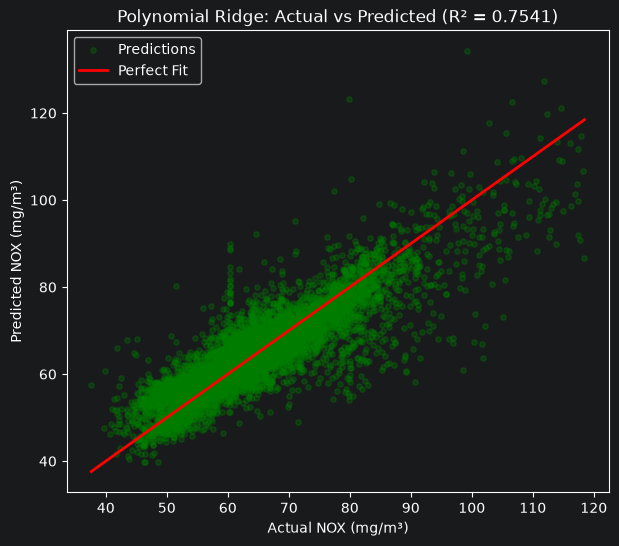

In [30]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_tuned, color='green', alpha=0.3, s=15, label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2, label='Perfect Fit')
plt.xlabel("Actual NOX (mg/m³)")
plt.ylabel("Predicted NOX (mg/m³)")
plt.title(f"Polynomial Ridge: Actual vs Predicted (R² = {tuned_poly_r2:.4f})")
plt.legend()
plt.show()